# 03 · SARIMA × SARIMAX: UFs e Brasil

**Etapa 3 — notebook principal, completo e reproduzível.** Pergunta central: incluir indicadores das tipologias de desastres melhora a previsão de mudanças na inadimplência em comparação com um modelo que já considera dinâmica temporal e sazonalidade?

**Análise principal:** 27 UFs × 2 períodos; triagem das 16 tipologias por estimabilidade **somente no treinamento**, com regressores reduzidos para UFs esparsas. **Análise complementar:** série nacional ponderada pelas carteiras, com **16 tipologias simultâneas** após validação do posto. Não há análise por grupos ou reclassificação de tipologias.

**Roteiro executável:** base, variáveis e splits → posto das 16 exógenas → suporte estadual → grade sazonal → ajuste *independente* SARIMA/SARIMAX por BIC no treino → comparação preditiva → comparação pareada de ordens iguais, LR exploratório → BH global e por modelo → diagnósticos de resíduos, warnings e gráficos → interpretação. Todo o código de ajuste fica neste notebook.

**Nota:** a estimação completa envolve cerca de 550 candidatos SARIMA/SARIMAX; executar tudo pode levar vários minutos. É possível retomar uma execução interrompida graças aos checkpoints por UF.

## 1. Dados, escala da resposta e treinamento

Resposta estadual: \(y_{i,t}=100\Delta\log(I_{i,t})\). Nacional: \(100\Delta\log(100\sum_i CI_{i,t}/\sum_i CA_{i,t})\) — não usamos média simples das taxas estaduais. Regressor \(X_{j,t}=\Delta\log(1+D_{j,t})\); no nacional, a soma de eventos entre UFs ocorre **antes** do log.

Treino pré-pandemia: fev/2013–jan/2019 (72 obs.), teste fev/2019–jan/2020 (12). Treino total: fev/2013–dez/2022 (119 obs.), teste jan/2023–dez/2024 (24). Os desastres do próprio mês são conhecidos na avaliação: trata-se de **previsão condicional**, não antecipação de eventos climáticos.

In [1]:
from pathlib import Path
import hashlib, os, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.diagnostic import acorr_ljungbox

# Executável a partir da raiz do repositório ou da pasta notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT=ROOT.parent
if not (ROOT/'data').exists():
    raise FileNotFoundError('Execute a partir da raiz do repositório ou de notebooks/.')
BASE = Path(os.environ.get('TCC_BASE_CSV',str(ROOT/'data/processed/df_tcc_2013_2024.csv')))
if not BASE.exists():
    raise FileNotFoundError(f'Base mensal não versionada: {BASE}. Consulte data/README.md.')
EXPECTED_HASH='46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36'
actual_sha=hashlib.sha256(BASE.read_bytes()).hexdigest()
assert actual_sha==EXPECTED_HASH, f'Hash da base diferente do painel auditado: {actual_sha}'
SOURCE=BASE
OUT=ROOT/'outputs/tables/revisao_estadual_20261019'
AUD=ROOT/'outputs/tables/auditoria_metodologica_20261020'
OUT.mkdir(parents=True,exist_ok=True)
AUD.mkdir(parents=True,exist_ok=True)
TIPOS=['tipo_alagamentos','tipo_chuvas_intensas','tipo_doencas_infecciosas','tipo_enxurradas','tipo_erosao','tipo_estiagem_e_seca','tipo_granizo','tipo_incendio_florestal','tipo_inundacoes','tipo_movimento_de_massa','tipo_onda_de_calor_e_baixa_umidade','tipo_onda_de_frio','tipo_outros','tipo_rompimento_colapso_de_barragens','tipo_tornado','tipo_vendavais_e_ciclones']
print('Base auditada:',BASE.name,'| SHA-256:',actual_sha[:16]+'…')

from scipy.stats import chi2
from statsmodels.tsa.statespace.sarimax import SARIMAX
# Para SARIMA/SARIMAX armazenamos todos os resultados em uma pasta auditável.
AR=ROOT/'outputs/tables/sarimax_criterios_independentes_20261020'
AR.mkdir(parents=True,exist_ok=True)
OUT=AR

Base auditada: df_tcc_2013_2024.csv | SHA-256: 46f4f8408f5f6a80…


In [2]:
def load():
    df=pd.read_csv(SOURCE,sep=';',encoding='utf-8-sig');df['data']=pd.to_datetime(df['mes_ano']+'-01');df=df.sort_values(['uf','data']).reset_index(drop=True)
    assert len(df)==3888 and df.uf.nunique()==27 and df.data.nunique()==144 and not df.duplicated(['uf','data']).any()
    assert len(TIPOS)==16 and not df[TIPOS].isna().any().any()
    assert np.allclose(100*df.carteira_inadimplencia_total/df.carteira_ativa_total,df.taxa_inadimplencia,rtol=0,atol=1e-9)
    assert np.isfinite(np.log(df.taxa_inadimplencia)).all() and (df[TIPOS]>=0).all().all()
    for c in ['taxa_inadimplencia']+TIPOS:
        df[('y' if c=='taxa_inadimplencia' else 'x_'+c)]=df.groupby('uf')[c].transform(lambda v: np.log(v).diff() if c=='taxa_inadimplencia' else np.log1p(v).diff())
    return df

df=load()
print("Séries estaduais:",df.uf.nunique(),"| meses:",df.mes_ano.nunique(),"| tipologias:",len(TIPOS))

Séries estaduais: 27 | meses: 144 | tipologias: 16


## 2. Grade sazonal e critérios de estimabilidade

Usamos `statsmodels.tsa.statespace.SARIMAX`. O `statsmodels` **não seleciona ordens automaticamente**; construímos uma grade explícita de cinco especificações com periodicidade anual `s=12`. As ordens temporais são selecionadas **separadamente para SARIMA e SARIMAX** pelo BIC do treino, entre candidatos convergidos. Também comparamos a ordem do melhor SARIMAX contra um SARIMA sem exógenas com a mesma ordem (pareamento).

Como aplicamos log-diferença externamente, `d=D=0` na grade ARMA. A série nacional consegue posto 16/16; na maioria dos estados não é possível identificar 16 coeficientes livres no treinamento. Por UF, incluímos tipologias com pelo menos **3 meses positivos no treino**, sem colinearidade, condicionamento padronizado ≤ 1.000 e no máximo 9 (pré) ou 12 (total) exógenas. A triagem **não depende de p ou RMSE do teste**.

In [3]:
MIN_MESES_COM_OCORRENCIA=3
MAX_EXOG={'Pré':9,'Total':12}
MAX_COND=1000.
MODELS=[((0,0,0),(1,0,0,12)),((1,0,0),(1,0,0,12)),((0,0,1),(1,0,0,12)),((1,0,1),(1,0,0,12)),((1,0,0),(0,0,1,12))]
PERIODS={'Pré':('2020-01','2019-01',72,12),'Total':('2024-12','2022-12',119,24)}
COLUMNS_X=['x_'+t for t in TIPOS]
print('Candidatos temporais sazonais:',MODELS)

Candidatos temporais sazonais: [((0, 0, 0), (1, 0, 0, 12)), ((1, 0, 0), (1, 0, 0, 12)), ((0, 0, 1), (1, 0, 0, 12)), ((1, 0, 1), (1, 0, 0, 12)), ((1, 0, 0), (0, 0, 1, 12))]


In [4]:
def predicted_1step(result, yall, xall, ntrain):
    # Previsão condicional, 1 passo: estado atualizado com y realizado até t-1.
    # Quando contemporâneo, x_t é observado, nunca inferido no instante t-1.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        mod = SARIMAX(np.asarray(yall,float),
                     exog=None if xall is None else np.asarray(xall,float),
                     order=result.model.order,
                     seasonal_order=result.model.seasonal_order,
                     trend='c', enforce_stationarity=True, enforce_invertibility=True)
        filtered = mod.filter(result.params)
        pred = np.asarray(filtered.get_prediction(start=ntrain,
                          end=len(yall)-1,dynamic=False).predicted_mean,float)
    true=np.asarray(yall[ntrain:],float)
    assert len(pred)==len(true) and np.isfinite(pred).all()
    return {'rmse':float(np.sqrt(np.mean((pred-true)**2))),
            'mae':float(np.mean(np.abs(pred-true))),
            'n_teste':len(true)}


def full_exog_audit(xtrain,xall,typologies):
    xt=np.asarray(xtrain,float);xa=np.asarray(xall,float)
    ptp=np.ptp(xt,axis=0)
    duplicates=[]
    for j in range(len(typologies)):
        for k in range(j):
            if np.allclose(xt[:,j],xt[:,k],rtol=0,atol=1e-12):
                duplicates.append([typologies[k],typologies[j]])
    return {'posto_treino':int(np.linalg.matrix_rank(xt)),
            'posto_completo':int(np.linalg.matrix_rank(xa)),
            'n_exog_original':int(xt.shape[1]),
            'n_constantes_treino':int((ptp<1e-12).sum()),
            'n_constantes_total':int((np.ptp(xa,axis=0)<1e-12).sum()),
            'tipologias_constantes_treino':[typologies[j] for j in np.where(ptp<1e-12)[0]],
            'duplicadas_treino':duplicates}


def screen_by_support(x, D, ntrain, period):
    """Seleção determinística, só por suporte e independência no treino.

    A ordem utiliza meses com registro, com empate decidido pela ordem TIPOS.
    Sem seleção de sinais, p-valores ou desempenho fora da amostra.
    """
    xtrain=np.asarray(x[:ntrain],float)
    dtrain=np.asarray(D[:ntrain],float)
    counts=(dtrain>0).sum(axis=0)
    choices=sorted(range(16),key=lambda i:(-counts[i],i))
    included=[];exclusions={}
    for j in choices:
        if counts[j]<MIN_MESES_COM_OCORRENCIA:
            exclusions[TIPOS[j]]='menos de 3 meses positivos no treinamento'
            continue
        if np.ptp(xtrain[:,j])<1e-12:
            exclusions[TIPOS[j]]='exposição transformada constante no treino'
            continue
        if len(included)>=MAX_EXOG[period]:
            exclusions[TIPOS[j]]='limite de parcimônia aplicado antes do ajuste'
            continue
        candidate=included+[j]
        Z=xtrain[:,candidate]
        scale=np.std(Z,axis=0)
        Zn=(Z-Z.mean(axis=0))/scale
        if np.linalg.matrix_rank(Zn)<len(candidate):
            exclusions[TIPOS[j]]='dependência linear no treinamento'
            continue
        if np.linalg.cond(Zn)>MAX_COND:
            exclusions[TIPOS[j]]='condicionamento elevado no treinamento'
            continue
        included.append(j)
    included=sorted(included)
    assert not included or np.linalg.matrix_rank(xtrain[:,included])==len(included)
    return included,exclusions,counts


def series_for_unit(df,unit,period):
    end,cut,ntr,nte=PERIODS[period]
    if unit=='Brasil':
        # A taxa nacional é ponderada pelos denominadores: não é média de UFs.
        full=(df[df.mes_ano<=end].groupby('mes_ano',sort=True)
              [['carteira_ativa_total','carteira_inadimplencia_total',*TIPOS]].sum())
        y=100*np.log(100*full.carteira_inadimplencia_total/full.carteira_ativa_total).diff().iloc[1:].to_numpy(float)
        X=np.log1p(full[TIPOS]).diff().iloc[1:].to_numpy(float)
        D=full[TIPOS].iloc[1:].to_numpy(float)
        months=full.index[1:].to_numpy()
    else:
        subset=df[(df.uf==unit)&(df.mes_ano<=end)].dropna(subset=['y']).sort_values('mes_ano')
        y=100*subset.y.to_numpy(float)
        X=subset[COLUMNS_X].to_numpy(float)
        D=subset[TIPOS].to_numpy(float)
        months=subset.mes_ano.to_numpy()
    assert len(y)==ntr+nte and len(X)==len(y)
    assert np.all(np.isfinite(y)) and np.all(np.isfinite(X))
    assert (months[ntr-1]==cut), (unit,period,months[ntr-1],cut)
    return y,X,D,months

In [5]:
audit=[]
for per in PERIODS:
    for uf in [*sorted(df.uf.unique()),'Brasil']:
        y,x,D,months=series_for_unit(df,uf,per)
        a=full_exog_audit(x[:PERIODS[per][2]],x,TIPOS)
        audit.append({'periodo':per,'unidade':uf,**a})
AUDIT=pd.DataFrame(audit)
print('Posto 16/16 no treinamento:')
display(AUDIT.groupby(['periodo','posto_treino']).size().rename('n').reset_index())
print('Brasil:');display(AUDIT[AUDIT.unidade=='Brasil'][['periodo','posto_treino','posto_completo','n_constantes_treino']])

Posto 16/16 no treinamento:


,periodo,posto_treino,n
0,Pré,2,1
1,Pré,5,1
2,Pré,6,1
3,Pré,7,2
4,Pré,8,5
5,Pré,9,2
6,Pré,10,2
7,Pré,11,3
8,Pré,12,3
9,Pré,13,1


Brasil:


,periodo,posto_treino,posto_completo,n_constantes_treino
27,Pré,16,16,0
55,Total,16,16,0


## 3. Estimação SARIMA/SARIMAX com seleção independente

Para cada UF×período e Brasil×período, ajustamos os 5 candidatos de SARIMA **e** os 5 candidatos de SARIMAX, selecionando o menor BIC entre convergidos dentro de cada família. Ajustamos somente no treinamento. As previsões de um passo usam observações anteriores reais de inadimplência e as exposições contemporâneas observadas, **sem atualizar os parâmetros com o teste**. Os regressores são padronizados apenas com estatísticas do treino.

Warnings de otimização/inicialização são capturados e associados ao candidato; uma tentativa não convergente pode ser repetida com mais iterações. O output conserva os problemas, em vez de silenciá-los. O LR pareado só é calculado com mesmas ordens e é exploratório porque a seleção foi adaptativa.

In [6]:
def fit_one(y,order,seasonal,X=None,maxiter=120):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter('always')
        with np.errstate(all='ignore'):
            mod=SARIMAX(np.asarray(y,float),exog=None if X is None else np.asarray(X,float),
                        order=order,seasonal_order=seasonal,trend='c',
                        enforce_stationarity=True,enforce_invertibility=True)
            res=mod.fit(disp=False,maxiter=maxiter,method='lbfgs')
    notes=sorted({str(w.category.__name__)+': '+str(w.message).replace('\n',' ')[:210] for w in caught})
    return res,bool(res.mle_retvals.get('converged',False)),notes


def pick(candidates):
    eligible=[x for x in candidates if x['convergiu'] and np.isfinite(x['BIC'])]
    return min(eligible,key=lambda x:(x['BIC'],x['idx'])) if eligible else None


def one_unit(df,uf,period):
    y,x,D,months=series_for_unit(df,uf,period)
    ntrain=PERIODS[period][2]
    if uf=='Brasil':
        idx=list(range(16))
        if np.linalg.matrix_rank(x[:ntrain])!=16:return {'unidade':uf,'periodo':period,'status':'posto nacional insuficiente'},[],[]
    else:
        idx,excl,cnt=screen_by_support(x,D,ntrain,period)
        if not idx:return {'unidade':uf,'periodo':period,'status':'nenhuma exógena elegível'},[],[]
    z=x[:ntrain,idx];means=z.mean(axis=0);scale=z.std(axis=0)
    Z=(x[:,idx]-means)/scale
    cand=[];fitobjs={}
    for j,(order,seasonal) in enumerate(MODELS):
        for flavor in ['SARIMA','SARIMAX']:
            tr=Z[:ntrain] if flavor=='SARIMAX' else None
            r={'unidade':uf,'periodo':period,'modelo':flavor,'idx':j,'ordem':str(order),
               'sazonal':str(seasonal),'n_exog':len(idx),'n_train':ntrain}
            try:
                fitted,converged,warns=fit_one(y[:ntrain],order,seasonal,tr)
                # Tenta novamente caso maxiter seja insuficiente; registra ambas as tentativas.
                if not converged:
                    fit2,conv2,notes2=fit_one(y[:ntrain],order,seasonal,tr,maxiter=240)
                    warns=sorted(set(warns+['primeira tentativa sem convergência']+notes2))
                    if conv2 or not converged:fitted,converged=fit2,conv2
                r.update(convergiu=converged,BIC=float(fitted.bic),AIC=float(fitted.aic),
                         ljungbox_p=float(acorr_ljungbox(fitted.resid,lags=[12],return_df=True).lb_pvalue.iloc[0]),
                         n_warnings=len(warns),warnings=' | '.join(warns),n_iteracoes=int(fitted.mle_retvals.get('iterations',0)))
                if converged and np.isfinite(r['BIC']):fitobjs[(flavor,j)]=fitted
            except Exception as exc:r.update(convergiu=False,erro=repr(exc)[:240],BIC=np.nan,n_warnings=0,warnings='')
            cand.append(r)
    best_base=pick([c for c in cand if c['modelo']=='SARIMA']);best_x=pick([c for c in cand if c['modelo']=='SARIMAX'])
    row={'unidade':uf,'periodo':period,'status':'estimado' if best_base and best_x else 'sem candidato convergido',
         'n_exog':len(idx),'tipologias':';'.join(TIPOS[i] for i in idx),'n_treino':ntrain,
         'n_teste':len(y)-ntrain,'posto_original_treino':int(np.linalg.matrix_rank(x[:ntrain]))}
    coefs=[]
    if not best_base or not best_x:return row,cand,coefs
    rb=fitobjs[('SARIMA',best_base['idx'])];rx=fitobjs[('SARIMAX',best_x['idx'])]
    # Estimativa de x via BIC, mantendo apenas y e x do treino.
    bpred=predicted_1step(rb,y,None,ntrain);xpred=predicted_1step(rx,y,Z,ntrain)
    row.update(ordem_sarima=best_base['ordem'],sazonal_sarima=best_base['sazonal'],
               ordem_sarimax=best_x['ordem'],sazonal_sarimax=best_x['sazonal'],
               bic_sarima=float(rb.bic),bic_sarimax=float(rx.bic),
               delta_BIC=float(rx.bic-rb.bic),
               rmse_sarima=bpred['rmse'],rmse_sarimax=xpred['rmse'],
               melhora_RMSE_pct=100*(1-xpred['rmse']/bpred['rmse']),
               mae_sarima=bpred['mae'],mae_sarimax=xpred['mae'],
               ljungbox_sarima=float(best_base['ljungbox_p']),
               ljungbox_sarimax=float(best_x['ljungbox_p']),
               warnings_sarima=int(best_base['n_warnings']),
               warnings_sarimax=int(best_x['n_warnings']))
    # Comparação pareada sob ordem escolhida pelo SARIMAX, sem novo ajuste a x.
    samebase=fitobjs.get(('SARIMA',best_x['idx']))
    if samebase is not None:
        pa=predicted_1step(samebase,y,None,ntrain)
        lr=max(0.,2*(rx.llf-samebase.llf));p=float(chi2.sf(lr,len(idx)))
        row.update(bic_sarima_ordem_sarimax=float(samebase.bic),
                   delta_BIC_pareado=float(rx.bic-samebase.bic),
                   rmse_sarima_ordem_sarimax=pa['rmse'],
                   melhora_RMSE_pareado_pct=100*(1-xpred['rmse']/pa['rmse']),
                   LR_condicional=lr,p_conjunto_condicional=p)
    for j,tip in enumerate(idx):
        par='x'+str(j+1)
        if par not in rx.param_names: continue
        ix=rx.param_names.index(par)
        coefs.append({'unidade':uf,'periodo':period,'tipologia':TIPOS[tip],
                      'coef_original':float(rx.params[ix]/scale[j]),
                      'se_original':float(rx.bse[ix]/scale[j]),
                      'p_individual':float(rx.pvalues[ix]),'crit':'BIC independente',
                      'n_exog_modelo':len(idx)})
    return row,cand,coefs


def persist(mode,per,models,candidates,coefs):
    a=pd.DataFrame(models);b=pd.DataFrame(candidates);c=pd.DataFrame(coefs)
    if 'p_conjunto_condicional' in a:
        valid=a.p_conjunto_condicional.notna();a['q_conjunto_BH']=np.nan
        if valid.any():a.loc[valid,'q_conjunto_BH']=multipletests(a.loc[valid,'p_conjunto_condicional'],method='fdr_bh')[1]
    if len(c):
        c['q_individual_BH_global']=multipletests(np.nan_to_num(c.p_individual,nan=1).clip(0,1),method='fdr_bh')[1]
    for name,d in [('modelos',a),('candidatos',b),('coeficientes',c)]:
        d.to_csv(OUT/f'{mode}_{per}_{name}.csv',index=False,encoding='utf-8-sig')
    return a,b,c


def run(mode,period):
    src=Path(os.environ.get('TCC_BASE_CSV',str(ROOT/'data/processed/df_tcc_2013_2024.csv')))
    sha=hashlib.sha256(src.read_bytes()).hexdigest()
    assert sha=='46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36', 'Base diferente da versão verificada; não reutilizar checkpoints'
    d=load();units=['Brasil'] if mode=='nacional' else sorted(d.uf.unique())
    models=[];candidates=[];coefs=[];clock=time.monotonic()
    oldfiles=[OUT/f'{mode}_{period}_{key}.csv' for key in ['modelos','candidatos','coeficientes']]
    if oldfiles[0].exists():
        models=pd.read_csv(oldfiles[0]).replace({np.nan:None}).to_dict('records')
        candidates=pd.read_csv(oldfiles[1]).replace({np.nan:None}).to_dict('records') if oldfiles[1].exists() else []
        coefs=pd.read_csv(oldfiles[2]).replace({np.nan:None}).to_dict('records') if oldfiles[2].exists() else []
        print('REANUDANDO',mode,period,'concluidos=',len(models),flush=True)
    done={m['unidade'] for m in models}
    for i,uf in enumerate(units,1):
        if uf in done:continue
        row,ca,co=one_unit(d,uf,period)
        models.append(row);candidates.extend(ca);coefs.extend(co)
        persist(mode,period,models,candidates,coefs)
        print(f'{mode} {period} {i}/{len(units)} {uf} status={row["status"]} exog={row.get("n_exog")} '
          f'BIC_delta={row.get("delta_BIC",float("nan")):.3f} RMSE_melhora={row.get("melhora_RMSE_pct",float("nan")):.2f}% '
          f'tempo={time.monotonic()-clock:.1f}s',flush=True)
    print('DONE',mode,period,'modelos',len(models),'tempo',time.monotonic()-clock,flush=True)

## 4. Execução completa (com checkpoints de segurança)

A célula seguinte roda todas as unidades e os dois períodos. Se encontrar checkpoints já produzidos pela **mesma base SHA-256 e mesma versão dos procedimentos**, retoma as UFs faltantes. Para recomputar literalmente cada candidato do zero, exclua os três CSV de checkpoint por modo/período antes de executar. **Não execute este notebook em paralelo com outros que escrevam nas mesmas pastas**.

**Padrão do notebook:** `FORCAR_REESTIMACAO=True` para refazer tudo ao usar *Run All*. Para retomar do checkpoint e economizar tempo após interrupção, ajuste para `False`.

In [7]:
# Padrão: execução completa em Run All. Para retomar um processamento
# interrompido sem recalcular os estados prontos, ajuste para False.
FORCAR_REESTIMACAO=True
if FORCAR_REESTIMACAO:
    for modo in ['estadual','nacional']:
        for periodo in ['Pré','Total']:
            for nome in ['modelos','candidatos','coeficientes']:
                checkpoint=AR/f'{modo}_{periodo}_{nome}.csv'
                if checkpoint.exists():checkpoint.unlink()
    print('Checkpoints anteriores limpos: todos os candidatos serão estimados novamente.')

inicio=time.perf_counter()
for modo in ['estadual','nacional']:
    for periodo in ['Pré','Total']:
        run(modo,periodo)
print('Ajustes completos/retomados em',round(time.perf_counter()-inicio,1),'s')

Checkpoints anteriores limpos: todos os candidatos serão estimados novamente.


estadual Pré 1/27 AC status=estimado exog=3 BIC_delta=11.967 RMSE_melhora=1.60% tempo=0.7s


estadual Pré 2/27 AL status=estimado exog=2 BIC_delta=5.277 RMSE_melhora=-8.52% tempo=1.6s


estadual Pré 3/27 AM status=estimado exog=8 BIC_delta=23.966 RMSE_melhora=-15.59% tempo=2.7s


estadual Pré 4/27 AP status=estimado exog=3 BIC_delta=8.511 RMSE_melhora=-8.17% tempo=3.4s


...

nacional Pré 1/1 Brasil status=estimado exog=16 BIC_delta=55.023 RMSE_melhora=-15.02% tempo=2.7s


DONE nacional Pré modelos 1 tempo 2.6770460470006583


nacional Total 1/1 Brasil status=estimado exog=16 BIC_delta=64.108 RMSE_melhora=-10.58% tempo=2.6s


DONE nacional Total modelos 1 tempo 2.633405388999563


Ajustes completos/retomados em 96.1 s


## 5. BH global, resultados por modelo e warnings

Corrigimos os p-valores de coeficientes em uma família global por análise estadual (e outra nacional); apresentamos também BH dentro de cada modelo como diagnóstico complementar. Os testes conjuntos são BH entre modelos. P-valores são **condicionais às ordens selecionadas** — não garantem inferência seletiva exata. Para interpretar previsões, ΔRMSE positivo na coluna *melhora_RMSE_pct* significa que o SARIMAX teve RMSE menor.

In [8]:
def sarimax():
    for mode in ('estadual','nacional'):
        models=pd.concat([pd.read_csv(AR/f'{mode}_{per}_modelos.csv') for per in ['Pré','Total']],ignore_index=True)
        candidates=pd.concat([pd.read_csv(AR/f'{mode}_{per}_candidatos.csv') for per in ['Pré','Total']],ignore_index=True)
        coefficients=pd.concat([pd.read_csv(AR/f'{mode}_{per}_coeficientes.csv') for per in ['Pré','Total']],ignore_index=True)
        if 'p_conjunto_condicional' in models.columns:
            mask=models.p_conjunto_condicional.notna()
            models['q_conjunto_BH_global']=np.nan
            models.loc[mask,'q_conjunto_BH_global']=multipletests(models.loc[mask,'p_conjunto_condicional'],method='fdr_bh')[1]
        if len(coefficients):
            coefficients['q_individual_BH_global']=multipletests(np.nan_to_num(coefficients.p_individual.to_numpy(float),nan=1),method='fdr_bh')[1]
            coefficients['q_individual_BH_modelo']=np.nan
            for _,ids in coefficients.groupby(['periodo','unidade']).groups.items():
                coefficients.loc[ids,'q_individual_BH_modelo']=multipletests(coefficients.loc[ids,'p_individual'].fillna(1),method='fdr_bh')[1]
        for tag,table in [('comparacao',models),('candidatos',candidates),('coeficientes',coefficients)]:
            table.to_csv(AR/f'{mode}_{tag}.csv',index=False,encoding='utf-8-sig')
        warning_candidates=candidates.loc[candidates.n_warnings.fillna(0)>0].copy()
        warning_candidates.to_csv(AR/f'{mode}_warnings.csv',index=False,encoding='utf-8-sig')
        sig=coefficients.loc[coefficients.q_individual_BH_global<.05].copy() if len(coefficients) else coefficients.copy()
        sig.to_csv(AR/f'{mode}_significativos_BH.csv',index=False,encoding='utf-8-sig')
        summary={
          'modo':mode,'total_unidades_periodos':len(models),
          'comparaveis':int(models.rmse_sarimax.notna().sum()),
          'melhora_RMSE':int((models.melhora_RMSE_pct>0).sum()),
          'melhora_BIC':int((models.delta_BIC<0).sum()),
          'mediana_melhora_RMSE_pct':float(models.melhora_RMSE_pct.median()),
          'sazonal_em_todos_candidatos':True,
          'busca_independente':True,
          'melhor_entre_5_candidatos_por_BIC':True,
          'diagnostico_LB_SARIMA_rejeita':int((models.ljungbox_sarima<.05).sum()),
          'diagnostico_LB_SARIMAX_rejeita':int((models.ljungbox_sarimax<.05).sum()),
          'candidatos_total':len(candidates),
          'candidatos_com_warnings':len(warning_candidates),
          'candidatos_nao_convergentes':int((candidates.convergiu.astype(str).str.lower()=='false').sum()),
          'coeficientes_totais':len(coefficients),
          'coeficientes_nominais':int((coefficients.p_individual<.05).sum()) if len(coefficients) else 0,
          'coeficientes_BH_global':len(sig),
          'testes_conjuntos_BH':int((models.q_conjunto_BH_global<.05).sum()) if 'q_conjunto_BH_global' in models else 0,
          'proveniencia':'df_tcc_2013_2024.csv SHA256 46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36',
          'observacoes':'Testes condicionais à seleção por BIC; exógenas contemporâneas observadas no teste.'}
        (AR/f'{mode}_resumo_final.json').write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding='utf-8')
        print(mode,json.dumps(summary,ensure_ascii=False))

In [9]:
sarimax()
ST=pd.read_csv(AR/'estadual_comparacao.csv');NT=pd.read_csv(AR/'nacional_comparacao.csv')
EST_CO=pd.read_csv(AR/'estadual_coeficientes.csv')
print('Estadual:',int(ST.rmse_sarimax.notna().sum()),'comparáveis; melhora RMSE:',int((ST.melhora_RMSE_pct>0).sum()),'melhora BIC:',int((ST.delta_BIC<0).sum()))
print('Nacional:',int(NT.rmse_sarimax.notna().sum()),'comparações')
display(NT[['periodo','n_exog','bic_sarima','bic_sarimax','rmse_sarima','rmse_sarimax','melhora_RMSE_pct','ljungbox_sarima','ljungbox_sarimax']].round(5))
print('Associações com BH global<5%:');display(EST_CO[EST_CO.q_individual_BH_global<.05][['unidade','periodo','tipologia','coef_original','p_individual','q_individual_BH_global']])

estadual {"modo": "estadual", "total_unidades_periodos": 54, "comparaveis": 53, "melhora_RMSE": 16, "melhora_BIC": 0, "mediana_melhora_RMSE_pct": -5.10296132054755, "sazonal_em_todos_candidatos": true, "busca_independente": true, "melhor_entre_5_candidatos_por_BIC": true, "diagnostico_LB_SARIMA_rejeita": 14, "diagnostico_LB_SARIMAX_rejeita": 13, "candidatos_total": 530, "candidatos_com_warnings": 38, "candidatos_nao_convergentes": 0, "coeficientes_totais": 395, "coeficientes_nominais": 14, "coeficientes_BH_global": 2, "testes_conjuntos_BH": 0, "proveniencia": "df_tcc_2013_2024.csv SHA256 46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36", "observacoes": "Testes condicionais à seleção por BIC; exógenas contemporâneas observadas no teste."}


nacional {"modo": "nacional", "total_unidades_periodos": 2, "comparaveis": 2, "melhora_RMSE": 0, "melhora_BIC": 0, "mediana_melhora_RMSE_pct": -12.803545739821786, "sazonal_em_todos_candidatos": true, "busca_independente": true, "melhor_entre_5_candidatos_por_BIC": true, "diagnostico_LB_SARIMA_rejeita": 2, "diagnostico_LB_SARIMAX_rejeita": 2, "candidatos_total": 20, "candidatos_com_warnings": 3, "candidatos_nao_convergentes": 0, "coeficientes_totais": 32, "coeficientes_nominais": 0, "coeficientes_BH_global": 0, "testes_conjuntos_BH": 0, "proveniencia": "df_tcc_2013_2024.csv SHA256 46f4f8408f5f6a809de2601b5c313ea52ee5992ed5a65ede5246c57d28767e36", "observacoes": "Testes condicionais à seleção por BIC; exógenas contemporâneas observadas no teste."}
Estadual: 53 comparáveis; melhora RMSE: 16 melhora BIC: 0
Nacional: 2 comparações


,periodo,n_exog,bic_sarima,bic_sarimax,rmse_sarima,rmse_sarimax,melhora_RMSE_pct,ljungbox_sarima,ljungbox_sarimax
0,Pré,16,320.16441,375.18786,1.86617,2.14654,-15.02391,0.04502,0.00517
1,Total,16,565.68578,629.79350,1.35418,1.49750,-10.58318,0.03466,0.02614


Associações com BH global<5%:


,unidade,periodo,tipologia,coef_original,p_individual,q_individual_BH_global
95,PE,Pré,tipo_enxurradas,1.159152,0.000116,0.022858
295,PE,Total,tipo_enxurradas,0.829787,0.000064,0.022858


## 6. Comparação dos 27 estados — BIC e previsão

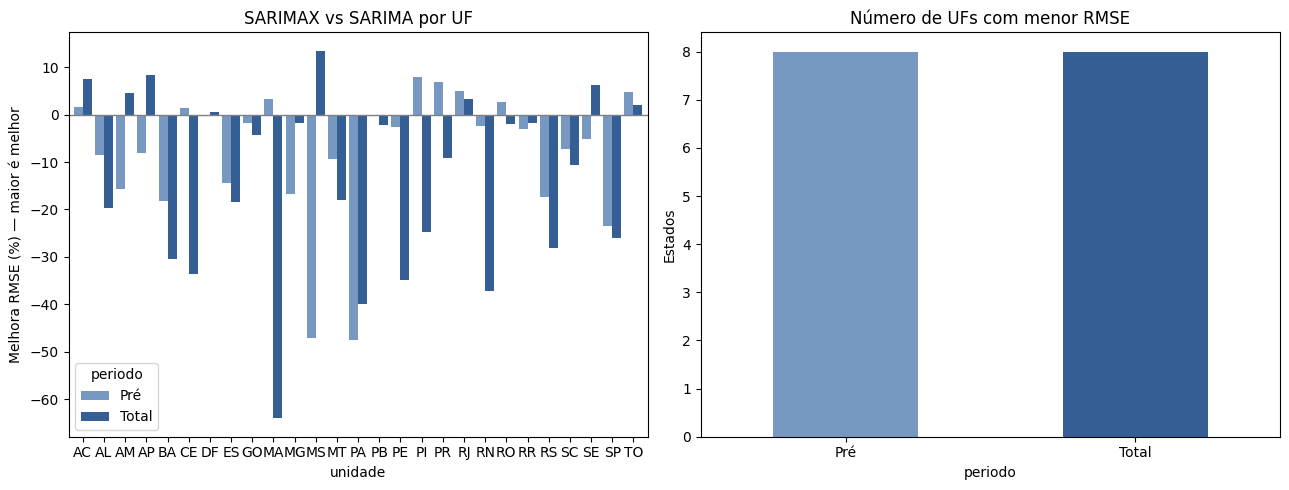

,unidade,periodo,n_exog,ordem_sarima,ordem_sarimax,delta_BIC,melhora_RMSE_pct,melhora_RMSE_pareado_pct,ljungbox_sarimax,q_conjunto_BH_global
0,AC,Pré,3.0,"(0, 0, 0)","(0, 0, 0)",11.9671,1.6001,1.6001,0.2565,0.9836
1,AL,Pré,2.0,"(0, 0, 0)","(0, 0, 0)",5.2772,-8.5199,-8.5199,0.1803,0.7680
2,AM,Pré,8.0,"(0, 0, 0)","(0, 0, 0)",23.9659,-15.5877,-15.5877,0.0099,0.7735
3,AP,Pré,3.0,"(0, 0, 0)","(0, 0, 0)",8.5105,-8.1706,-8.1706,0.5483,0.7680
4,BA,Pré,8.0,"(0, 0, 0)","(0, 0, 0)",15.9911,-18.2706,-18.2706,0.2002,0.5830
5,CE,Pré,9.0,"(0, 0, 0)","(0, 0, 0)",33.4369,1.4572,1.4572,0.4734,0.9836
6,DF,Pré,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,ES,Pré,9.0,"(0, 0, 0)","(0, 0, 0)",32.4266,-14.4315,-14.4315,0.2170,0.9836
8,GO,Pré,8.0,"(0, 0, 0)","(0, 0, 0)",28.4091,-1.6854,-1.6854,0.0578,0.9836
9,MA,Pré,5.0,"(0, 0, 0)","(0, 0, 0)",20.6943,3.3800,3.3800,0.0473,0.9836


In [10]:
T=ST.pivot(index='unidade',columns='periodo',values='melhora_RMSE_pct')
fig,axs=plt.subplots(1,2,figsize=(13,5))
T[['Pré','Total']].plot.bar(ax=axs[0],width=.85,color=['#7798c1','#345e94']);axs[0].axhline(0,color='gray',linewidth=1)
axs[0].set_ylabel('Melhora RMSE (%) — maior é melhor');axs[0].set_title('SARIMAX vs SARIMA por UF');axs[0].tick_params(axis='x',rotation=0)
(ST.groupby('periodo').melhora_RMSE_pct.apply(lambda x:int((x>0).sum())).reindex(['Pré','Total'])).plot.bar(ax=axs[1],color=['#7798c1','#345e94']);axs[1].set_title('Número de UFs com menor RMSE');axs[1].set_ylabel('Estados');axs[1].tick_params(axis='x',rotation=0)
plt.tight_layout();plt.show()
display(ST[['unidade','periodo','n_exog','ordem_sarima','ordem_sarimax','delta_BIC','melhora_RMSE_pct','melhora_RMSE_pareado_pct','ljungbox_sarimax','q_conjunto_BH_global']].sort_values(['periodo','unidade']).reset_index(drop=True).round(4))

## 7. Diagnósticos de resíduos e log completo de warnings

O teste Ljung–Box verifica se restou autocorrelação até 12 meses. Rejeitar H₀ sinaliza que o modelo ainda deixa dependência serial; isso não impede o ajuste numérico, mas enfraquece a inferência e recomenda cautela. Distinga warnings de inicialização, de convergência e diagnóstico residual; o notebook não os omite.

In [11]:
for modo,tab in [('estadual',ST),('nacional',NT)]:
    W=pd.read_csv(AR/f'{modo}_warnings.csv')
    C=pd.read_csv(AR/f'{modo}_candidatos.csv')
    print(modo,': candidatos=',len(C),'com warnings=',len(W),'não convergentes=',int((C.convergiu.astype(str).str.lower()=='false').sum()),'modelos SARIMAX com LB<.05=',int((tab.ljungbox_sarimax<.05).sum()))
    if len(W): display(W[['unidade','periodo','modelo','ordem','sazonal','n_warnings','warnings']].head(12))

estadual : candidatos= 530 com warnings= 38 não convergentes= 0 modelos SARIMAX com LB<.05= 13


,unidade,periodo,modelo,ordem,sazonal,n_warnings,warnings
0,AL,Pré,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",1,UserWarning: Non-invertible starting MA parame...
1,AL,Pré,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
2,AM,Pré,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
3,BA,Pré,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
4,CE,Pré,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
5,CE,Pré,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
6,ES,Pré,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
7,ES,Pré,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
8,GO,Pré,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
9,GO,Pré,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...


nacional : candidatos= 20 com warnings= 3 não convergentes= 0 modelos SARIMAX com LB<.05= 2


,unidade,periodo,modelo,ordem,sazonal,n_warnings,warnings
0,Brasil,Pré,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
1,Brasil,Pré,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...
2,Brasil,Total,SARIMA,"(1, 0, 1)","(1, 0, 0, 12)",2,UserWarning: Non-invertible starting MA parame...


## 8. Interpretação e reprodução

A análise estadual original com 16 coeficientes livres é **não identificável em 53 dos 54 treinos**; a redução por suporte torna 53 pares comparáveis. Compare **SARIMA e SARIMAX selecionados independentemente pelo BIC** para julgar parcimônia global, e as ordens iguais para avaliar o incremento das exógenas. A série nacional usa 16 tipologias simultâneas. Resultados BH não implicam efeito causal; as séries pré e total se sobrepõem, e os regressors `X_t` do mês da previsão já são observados no cenário condicional.

**Arquivos gerados:** `outputs/tables/sarimax_criterios_independentes_20261020/{estadual,nacional}_{comparacao,candidatos,coeficientes,warnings,significativos_BH}.csv` e `*_resumo_final.json`. O notebook contém o mecanismo de seleção, execução, correção BH, gráficos e tabelas: nenhum outro script `src/` é necessário.